In [3]:
# Persiapan Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

In [4]:
# Dataset sintetis untuk simulasi (dapat diganti dataset nyata, mis. UCI/Kanggle)
X,y = make_classification(n_samples=1000,n_features=10,
                          n_informative=6,weights=[0.8,0.2],random_state=42)
print("Distribusi kelas:", np.bincount(y))

Distribusi kelas: [797 203]


In [5]:
data = pd.read_csv(r"C:\Users\rhyma\anaconda_projects\WA_Fn-UseC_-Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Prepocessing:Stratified Split
X_train,X_test,y_train,y_test = train_test_split( X,y,
                                                  test_size=0.2,random_state=42,stratify=y)
print("Proporsi kela train:",
      np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :",
      np.bincount(y_test) / len(y_test))

Proporsi kela train: [0.7975 0.2025]
Proporsi kelas test : [0.795 0.205]


In [5]:
# Training Model & Learning Curve
model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes,train_scores, val_scores = learning_curve( model,X_train,y_train,
                                                       cv=5,train_sizes=np.linspace(0.1,1.0,8),
                                                       scoring="accuracy" )
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [6]:
train_sizes

array([ 64, 146, 228, 310, 393, 475, 557, 640])

In [7]:
# Evaluasi
print("Skor train pada ukuran data terbesar :",
      round(train_mean[-1],3))
print("Skor validasi pada ukuran data terbesar:",
      round(val_mean[-1],3))
print("Gap (indikasi overfitting jika besar) :",
      round(train_mean[-1] - val_mean[-1],3))

Skor train pada ukuran data terbesar : 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar) : 0.044


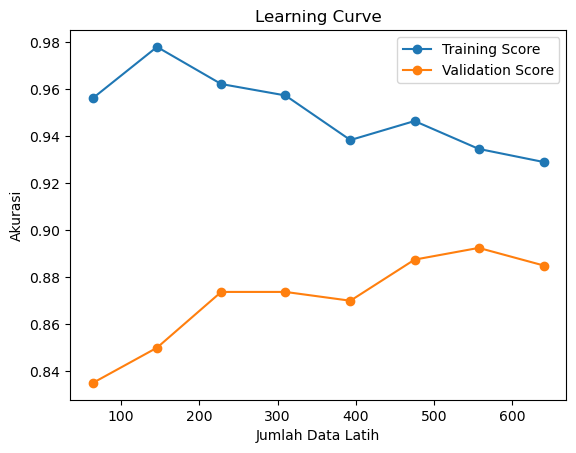

In [10]:
# Visualisasi 
plt.plot(train_sizes,train_mean,'o-',
         label='Training Score')
plt.plot(train_sizes,val_mean,'o-',
         label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')
plt.legend()
plt.show()